In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

data = {
    'Age': [ 'Youth', 'Youth', 'Middle', 'Senior', 'Senior', 'Middle', 'Senior',
           'Youth', 'Youth', 'Senior', 'Youth', 'Middle', 'Middle', 'Senior'],

    'Income': [ 'High', 'High', 'High', 'Medium', 'Low', 'Low', 'Low', 'Medium',
              'Low', 'Medium', 'Medium', 'Medium', 'High', 'Medium'],

    'Student': [ 'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes',
               'Yes', 'No', 'Yes', 'No'],

    'CreditRating': [ 'Fair', 'Excellent', 'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent',
                    'Fair', 'Fair', 'Fair', 'Excellent', 'Excellent', 'Fair', 'Excellent'],

    'BuysComputer': [ 'No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes',
                      'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)
df

,Age,Income,Student,CreditRating,BuysComputer
0,Youth,High,No,Fair,No
1,Youth,High,No,Excellent,No
2,Middle,High,No,Fair,Yes
3,Senior,Medium,No,Fair,Yes
4,Senior,Low,Yes,Fair,Yes
5,Middle,Low,Yes,Excellent,No
6,Senior,Low,Yes,Excellent,Yes
7,Youth,Medium,No,Fair,No
8,Youth,Low,Yes,Fair,Yes
9,Senior,Medium,Yes,Fair,Yes


In [ ]:
#ENCODE CATEGORICAL -> NUMERIC

le = {}  # create empty dictionary
df_enc = df.copy()  # here we just cop our original data
for col in df.columns:  # it convert into the text using loop through of the column
    le[col] = LabelEncoder()  # now create new label for current data
    df_enc[col] = le[col].fit_transform(
        df[col]
    )  # its learn unique value and transform text to value

df_enc

,Age,Income,Student,CreditRating,BuysComputer
0,2,0,0,1,0
1,2,0,0,0,0
2,0,0,0,1,1
3,1,2,0,1,1
4,1,1,1,1,1
5,0,1,1,0,0
6,1,1,1,0,1
7,2,2,0,1,0
8,2,1,1,1,1
9,1,2,1,1,1


In [ ]:
#FEATURES AND TARGET
x = df_enc[['Age', 'Income', 'Student', 'CreditRating']]
y = df_enc['BuysComputer']

x

,Age,Income,Student,CreditRating
0,2,0,0,1
1,2,0,0,0
2,0,0,0,1
3,1,2,0,1
4,1,1,1,1
5,0,1,1,0
6,1,1,1,0
7,2,2,0,1
8,2,1,1,1
9,1,2,1,1


In [ ]:
y

,BuysComputer
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [ ]:
model = CategoricalNB() #apply model
model.fit(x, y) #here fit your values

CategoricalNB()

In [ ]:
test = [['Youth', 'Medium', 'Yes', 'Fair']] #Testing data

In [ ]:
test

[['Youth', 'Medium', 'Yes', 'Fair']]

In [ ]:
print("\n---Precdiction--------------------------------------------")
for t in test:
  row = [[le['Age'].transform([t[0]])[0],
          le['Income'].transform([t[1]])[0],
          le['Student'].transform([t[2]])[0],
          le['CreditRating'].transform([t[3]])[0]
  ]]
  pred = le['BuysComputer'].inverse_transform(model.predict(row))[0]
  prob = model.predict_proba(row)[0]
  print(f"Input : Age={t[0]}, Income={t[1]}, Student={t[2]}, CreditRating={t[3]}")
  print(f"Result : BuysComputer={pred}")
  print(f"P(No) = {prob[0]:.4f}")
  print(f"P(Yes) = {prob[1]:.4f}")





---Precdiction--------------------------------------------
Input : Age=Youth, Income=Medium, Student=Yes, CreditRating=Fair
Result : BuysComputer=Yes
P(No) = 0.2322
P(Yes) = 0.7678


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 78.57%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


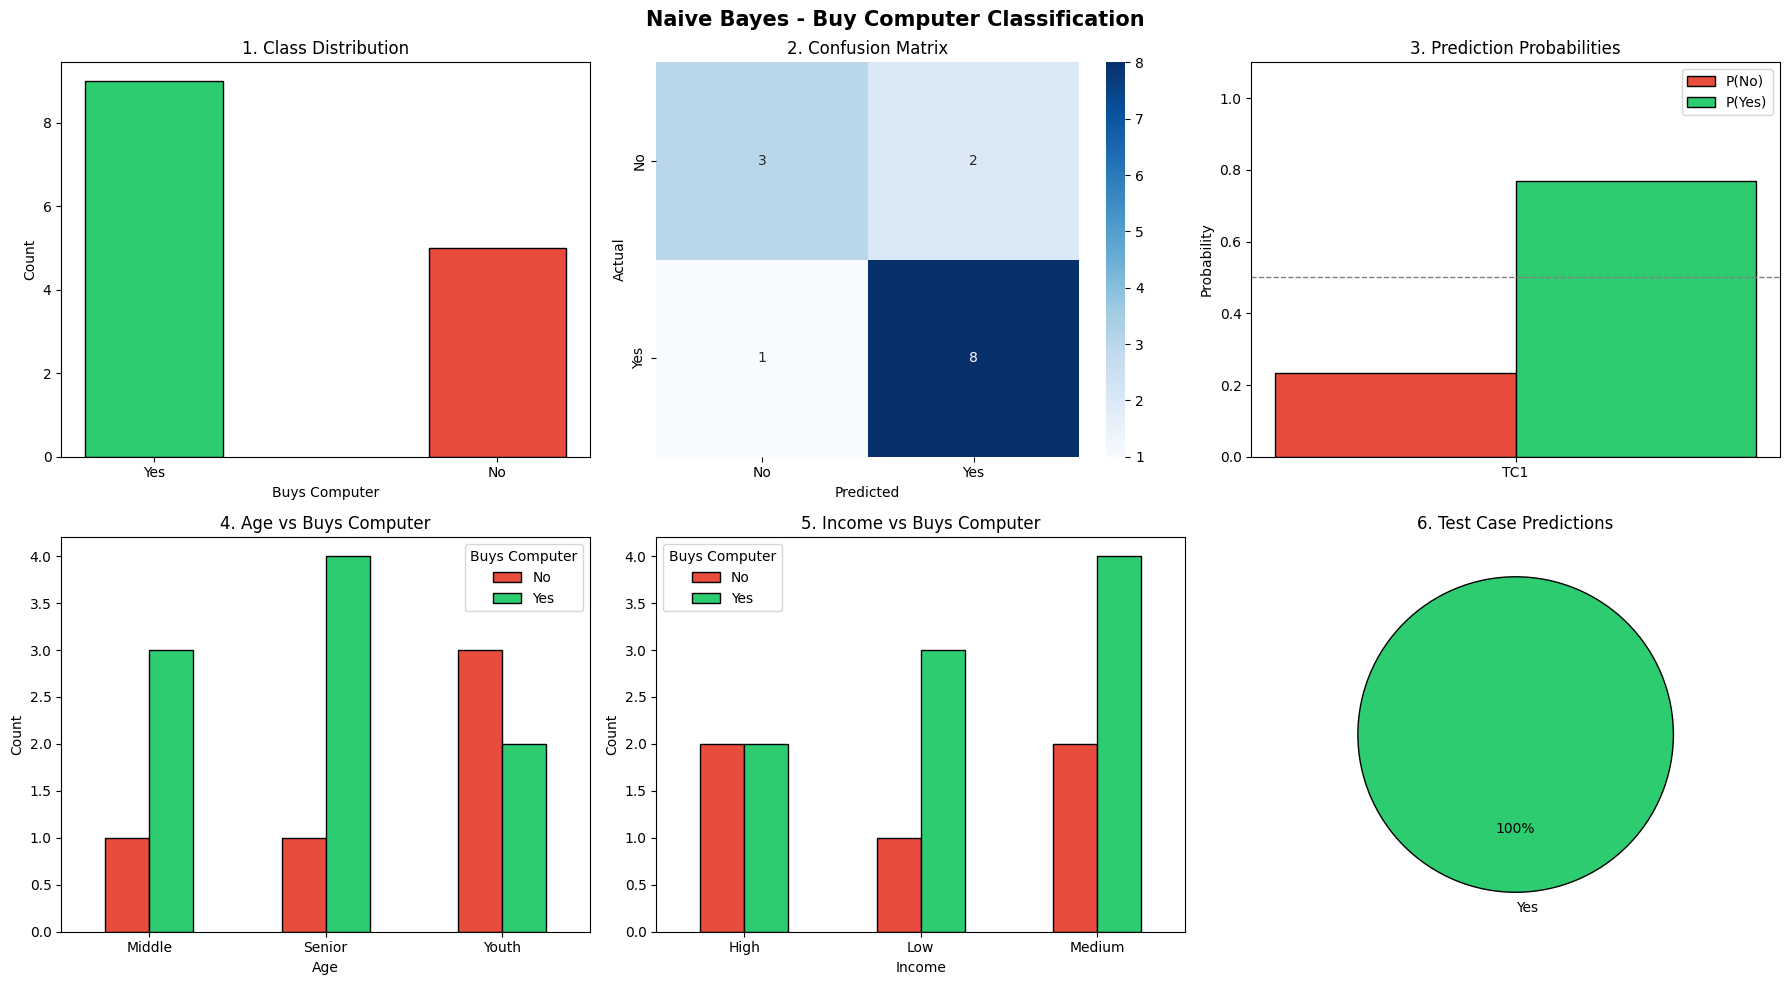

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Prepare prediction probabilities and predictions list for the test cases
probs_no = []
probs_yes = []
predictions = []
for t in test:
    row = [[
        le['Age'].transform([t[0]])[0],
        le['Income'].transform([t[1]])[0],
        le['Student'].transform([t[2]])[0],
        le['CreditRating'].transform([t[3]])[0]
    ]]
    prob = model.predict_proba(row)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])

    # Generate predicted class name
    pred_class = le['BuysComputer'].inverse_transform(model.predict(row))[0]
    predictions.append(pred_class)

# Correct grid to 2 rows and 3 columns to host all 6 plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    "Naive Bayes - Buy Computer Classification", fontsize=15, fontweight="bold"
)

# 1. Class Distribution
counts = df["BuysComputer"].value_counts()
axes[0, 0].bar(
    counts.index,
    counts.values,
    color=["#2ecc71", "#e74c3c"], # Yes: green, No: red
    edgecolor="black",
    width=0.4,
)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Buys Computer")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix (Explicitly using the correct feature DataFrame to avoid variable collisions with 'x')
features_data = df_enc[['Age', 'Income', 'Student', 'CreditRating']]
cm = confusion_matrix(y, model.predict(features_data))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_indices = np.arange(len(tc_labels))
w = 0.35
axes[0, 2].bar(x_indices - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_indices + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Age vs BuysComputer
age_counts = df.groupby(['Age', 'BuysComputer']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71'],
                edgecolor='black', rot=0)
axes[1, 0].set_title("4. Age vs Buys Computer")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="Buys Computer")

# 5. Income vs BuysComputer
inc_counts = df.groupby(['Income', 'BuysComputer']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71'],
                edgecolor='black', rot=0)
axes[1, 1].set_title("5. Income vs Buys Computer")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="Buys Computer")

# 6. Test Case Predictions (Pie Chart)
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if label == 'Yes' else '#e74c3c' for label in pred_counts.index]

axes[1, 2].pie(
    pred_counts.values,
    labels=pred_counts.index,
    autopct="%1.0f%%",
    colors=colors_pie,
    startangle=90,
    wedgeprops={'edgecolor': 'black'}
)
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()